In [ ]:
%pip install puremacro


# Flujos DSGE no lineales: ejecución ordenada de `.mod`, políticas globales de Chebyshev y transiciones Newton–Krylov con restricciones

**Cuando vamos más allá de la perturbación lineal, ¿cómo verificamos que la ejecución ordenada de programas `.mod`, las expansiones de Taylor de orden superior, la iteración temporal global de Chebyshev y las transiciones de previsión perfecta con restricciones coincidan donde deben hacerlo y revelen no linealidades económicas genuinas donde difieren?**

Las aproximaciones por perturbación de primer orden asumen equivalencia con certidumbre y ajustes simétricos, lo que implica que los agentes toman decisiones como si las perturbaciones futuras fueran nulas en promedio. En la práctica, la macroeconomía moderna es profundamente no lineal y asimétrica: los hogares acumulan ahorro precautorio frente a ingresos volátiles, la política monetaria se enfrenta a la cota inferior efectiva sobre los tipos de interés nominales ($i_t \ge i_{\text{elb}}$) y las empresas operan bajo suelos de irreversibilidad en la inversión en capital ($i_t \ge i_{\min}$). Para analizar estas realidades, los economistas emplean perturbaciones de orden superior (aproximaciones de Taylor de segundo y tercer orden), métodos globales de proyección (iteración temporal con colocación de Chebyshev) y algoritmos de Newton apilados en el tiempo con restricciones. Sin embargo, cada enfoque numérico introduce aproximaciones singulares y modos de fallo sutiles: los programas `.mod` de múltiples fases pueden filtrar involuntariamente el estado de calibración entre etapas; los sistemas de Sylvester de orden superior pueden sufrir acoplamiento fuera de la diagonal de Schur; la colocación en producto tensorial arriesga una asignación de memoria explosiva debido a matrices densas de Vandermonde; y los horizontes finitos truncados distorsionan las transiciones de previsión perfecta. Este cuaderno establece una batería de verificación unificada y reproducible en cuatro modelos macroeconómicos de referencia y registra once auditorías numéricas rigurosas en un único cuadro de comprobaciones.

| Alcance y verificación | |
|---|---|
| Flujos cubiertos | 1. Ejecución ordenada de `.mod` en múltiples fases con recalibración intermedia y `histval` con múltiples rezagos; 2. Condicionamiento de Sylvester de tercer orden e iteración temporal separable de Chebyshev (`orders=(8, 8)`); 3. Mapa de precisión local frente a global (`sigma=1.0` frente al límite sin riesgo `sigma=0.0`); 4. Transiciones MCP con restricciones mediante Newton–Krylov libre de matrices frente a factorización directa dispersa (`mcp=True`, `terminal_policy`) |
| Modelos | Modelo RBC con productividad AR(2) de dos rezagos y cambio intermedio en la participación del capital; modelo RBC estocástico CRRA de 2 estados; modelo RBC con inversión irreversible `[mcp = 'i > i_min']`; modelo neokeynesiano no lineal con cota inferior efectiva `[mcp = 'i > i_elb']` |
| Solucionadores y diagnósticos | `inspect_mod`, `read_mod().execute_mod_commands()`, `diagnose_perturbation`, `evaluate_perturbation`, `EquilibriumProblem.from_model`, `solve_time_iteration`, `compare_policies`, `solve_transition(..., linear_solver="direct" | "krylov")` |
| Aceptación | Inmutabilidad de instantáneas y paridad frente a ejecución independiente $<10^{-12}$; residuos algebraicos de Sylvester $<10^{-13}$; residuos de Euler de Chebyshev separable $<10^{-8}$ sin alojar matrices densas de colocación; acuerdo entre trayectorias MCP directas y Krylov libre de matrices $<10^{-9}$ con cero bloques JVP densos |


## El método en matemáticas

**1. Operadores de Sylvester de orden superior y condicionamiento.** Alrededor del estado estacionario determinista $y^*$, la perturbación de primer orden produce la transición de estados $H_x$ y el haz adelantado $(\hat A, A_+)$ con $\hat A = A_0 + A_+ G_x P_s$. El tensor de curvatura de estados de orden $k$, $G_k$, resuelve la ecuación generalizada de Sylvester
$$\mathcal{L}_k(G_k) = \hat A\, G_k + A_+\, G_k\, H_x^{\otimes k} = -K_k, \qquad k \in \{2, 3\}.$$
La descomposición real de Schur $H_x = U T U^\top$ reduce $\mathcal{L}_k$ a sistemas por bloques triangulares de Bartels–Stewart a lo largo de los bloques diagonales de $T^{\otimes k}$, aprovechando la simetría de permutación sobre tuplas de índices ordenadas $(i_1 \le \dots \le i_k)$. Como la no normalidad y el acoplamiento fuera de la diagonal en $T$ pueden amplificar errores incluso cuando los haces diagonales individuales $\hat A + \tau A_+$ están bien condicionados, `diagnose_perturbation()` reporta tanto el peor número de condición de los bloques diagonales de Schur como el número de condición en norma 1, $\kappa_1(\mathcal{L}_k) = \|\mathcal{L}_k\|_1 \|\mathcal{L}_k^{-1}\|_1$, del operador completo de curvatura, junto con los residuos algebraicos normalizados de `ghxx`, `ghs2`, `ghxxx`, `ghxss` y `ghuss`.

**2. Colocación separable de Chebyshev e iteración temporal global.** En una malla de estados en producto tensorial $\mathcal{G} = \mathcal{G}_1 \times \dots \times \mathcal{G}_d$ de tamaño $M = \prod_{j=1}^d (n_j + 1)$, ajustar los coeficientes de Chebyshev formando la matriz densa de Vandermonde $M \times M$ requiere trabajo de factorización $\mathcal{O}(M^3)$ y memoria $\mathcal{O}(M^2)$. Aprovechar la separabilidad de Kronecker $V = V_1 \otimes \dots \otimes V_d$ factoriza cada matriz 1D de Vandermonde $V_j \in \mathbb{R}^{(n_j+1)\times(n_j+1)}$ una sola vez y actualiza los coeficientes mediante contracciones tensoriales secuenciales en cada modo $j$. En cada nodo $s \in \mathcal{G}$, la iteración temporal resuelve el sistema de equilibrio condicional
$$\mathbb{E}\!\left[\,F\big(y_{-}(s),\, y(s, x),\, y(s', g^{(m)}(s')),\, \varepsilon'\big)\,\right] = 0$$
para los controles actuales $x$, empleando derivadas simbólicas exactas del DAG compilado del archivo `.mod` mediante `TrajectoryJacobian` y derivadas analíticas de la base de Chebyshev $\partial g^{(m)}(s')/\partial s'$.

**3. Transiciones apiladas en el tiempo con restricciones y políticas terminales.** En un horizonte finito $t = 1, \dots, T$, la previsión perfecta apilada en el tiempo ensambla el sistema no lineal por bloques $R_t(y_{t-1}, y_t, y_{t+1}, u_t) = 0$. Cuando el estado aún no ha regresado a $y^*$ en el período $T$, cerrar el adelanto terminal con $y_{T+1} = g_{\text{term}}(y_T)$ modifica la última columna de bloques a $A_{0,T} + A_{+,T} J_{\text{term}}$. Bajo restricciones de desigualdad $l_t \le y_t \le u_t$ declaradas mediante `[mcp = '...']`, el sistema KKT / Fischer–Burmeister de conjunto activo impone la complementariedad $0 \le y_t - l_t \perp R_t(y) \ge 0$, evaluada ya sea mediante LU directa dispersa o mediante LGMRES precondicionado libre de matrices usando los bloques jacobianos dispersos en caché $(A_{-,t}, A_{0,t}, A_{+,t})$.


## Intuición

Ir más allá de la perturbación lineal transforma profundamente las preguntas económicas que podemos responder, pero también exige una clara separación conceptual entre las distintas fuentes de no linealidad:

**La ejecución ordenada de `.mod` como protocolo experimental inmutable.** El análisis de política macroeconómica a menudo requiere evaluar experimentos en múltiples etapas, como una reforma estructural imprevista en la que las autoridades aumentan de forma permanente la participación del capital en el ingreso $\alpha$ o introducen un impuesto al carbono. Históricamente, gestionar recalibraciones secuenciales en un único archivo conllevaba riesgos severos: si un algoritmo muta variables globales in situ, las trayectorias base y los estados estacionarios previos se corrompen en silencio. En PureMacro, la ejecución ordenada trata el archivo `.mod` como un protocolo experimental reproducible. Reasignar un parámetro estructural a mitad del flujo actualiza automáticamente todas las definiciones derivadas posteriores (como el ratio capital-trabajo `cap_ratio`), recalcula el nuevo estado estacionario y lanza transiciones dinámicas manteniendo inmutables las instantáneas históricas. Los estados predeterminados con múltiples rezagos (como un proceso AR(2) de productividad que exige dos condiciones iniciales en `histval`) se conservan con exactitud histórica.

**Separación entre desplazamientos por riesgo y curvatura determinista de estado.** Al contrastar las reglas locales de Taylor con las funciones de política no lineales globales, los economistas deben distinguir entre la curvatura intrínseca de la regla y el desplazamiento inducido por la incertidumbre macroeconómica. Una regla de perturbación de primer orden es estrictamente lineal y satisface la certidumbre equivalente. Una expansión de segundo orden incorpora tanto la curvatura cuadrática del estado $\frac{1}{2} G_{xx} (x_t^{(1)})^{\otimes 2}$ como un desplazamiento constante por riesgo precautorio $\frac{1}{2} g_{\sigma\sigma} \sigma^2$. Una expansión de tercer orden añade correcciones de riesgo dependientes del estado $\frac{1}{2} g_{x\sigma\sigma} \sigma^2 x_t^{(1)}$. Cuando evaluamos la perturbación con $\sigma = 1.0$, la regla refleja tanto la aversión al riesgo del agente como la varianza de los choques futuros, aproximándose con gran fidelidad a la política estocástica global obtenida por iteración temporal de Chebyshev cerca del estado estacionario. Por el contrario, evaluar la expansión con $\sigma = 0.0$ elimina los motivos precautorios, aislando la curvatura determinista pura que rige las transiciones de previsión perfecta.

**Transiciones con restricciones, complementariedad de conjunto activo y condiciones de frontera.** Las restricciones económicas rígidas —como el suelo de irreversibilidad de la inversión ($i_t \ge i_{\min}$) o la cota inferior sobre los tipos de interés nominales ($i_t \ge i_{\text{elb}}$)— generan quiebres no diferenciables en las reglas de política. La simulación apilada en el tiempo sobre un horizonte finito $t = 1, \dots, T$ formula estas restricciones como un Problema de Complementariedad Mixta (MCP), garantizando que la condición de holgura complementaria $0 \le y_t - l_t \perp R_t(y) \ge 0$ se satisfaga en cada período. Comparar las factorizaciones directas LU dispersas frente a solucionadores de Newton–Krylov libres de matrices con bloques jacobianos dispersos en caché demuestra que las iteraciones de Krylov alcanzan precisión de máquina sin requerir el ensamblaje de enormes matrices $NT \times NT$. Asimismo, dado que una simulación en horizonte finito debe truncar el futuro, imponer $y_{T+1} = y^*$ genera distorsiones artificiales en la frontera siempre que el capital no haya regresado al estado estacionario en el período $T$. Proporcionar una regla de política terminal de primer orden `terminal_policy` elimina estas distorsiones de frontera al permitir que el sistema escape a lo largo de la trayectoria de silla estable.


## Código resuelto

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

repo = Path.cwd() if (Path.cwd() / "puremacro").is_dir() else Path.cwd().parent
sys.path.insert(0, str(repo))
sys.path.insert(0, str(repo / "notebooks"))
import _nbstyle
_nbstyle.apply_style()

from puremacro.dsge import (
    EquilibriumProblem,
     audit_policy,
    compare_policies,
    diagnose_perturbation,
    evaluate_perturbation,
    gaussian_quadrature,
    inspect_mod,
    load_mod,
    read_mod,
    solve_time_iteration,
    solve_transition,
)

checks = []


def record(result, measured, bound, verdict):
    checks.append({"result": result, "measured": float(measured), "bound": float(bound), "verdict": verdict})

### 1. Ejecución ordenada de `.mod` con recalibración intermedia y `histval` de múltiples rezagos

**Motivación económica.** Los economistas dedicados al diseño de políticas con frecuencia modelan quiebres estructurales y reformas de medio plazo. Consideremos una economía que experimenta una variación permanente en la elasticidad del producto respecto al capital, pasando de $\alpha = 0.33$ a $\alpha = 0.36$. Dicha reforma altera la distribución factorial del ingreso, eleva el ratio capital-producto óptimo e induce una prolongada transición de acumulación de capital. Evaluar esta reforma en un único archivo `.mod` exige resolver el estado estacionario inicial anterior a la reforma, reasignar parámetros en mitad de la ejecución, actualizar relaciones estructurales derivadas como `cap_ratio = alpha / (1 - alpha)`, resolver el estado estacionario terminal y simular la trayectoria de transición dinámica, garantizando en todo momento que los resultados iniciales permanezcan estrictamente aislados y reproducibles.

**Mecanismo matemático.** En modelos dinámicos con retardos de múltiples períodos, el espacio de estados debe registrar todas las variables predeterminadas. En este caso, la productividad total de los factores sigue un proceso autorregresivo con dos rezagos, $a_t = \rho_1 a_{t-1} + \rho_2 a_{t-2} + e_t$, por lo que tanto $a(0)$ como $a(-1)$ representan condiciones históricas predeterminadas genuinas que deben especificarse en `histval`. El compilador genera una variable de estado auxiliar `AUX_LAG_a_1` para dotar a la dinámica AR(2) de una representación de Markov de primer orden. Cuando el programa actualiza $\alpha = 0.36$, las ecuaciones de estado estacionario recalculan el stock de capital de largo plazo $k^* = \left(\frac{\alpha}{\beta^{-1} - (1-\delta)}\right)^{\frac{1}{1-\alpha}}$, incrementando el capital de $28.35$ a $34.48$.

**Paso a paso del código comentado.** Proporcionamos `ORDERED_MOD` a `inspect_mod(ordered=True)` para certificar la cobertura estática y la integridad de las dependencias. A continuación, `read_mod(ORDERED_MOD).execute_mod_commands()` procesa secuencialmente cada bloque de instrucciones, generando comprobantes de ejecución con instantáneas herméticas. Finalmente, verificamos que la transición de la Fase 2 generada por el programa ordenado coincide con una llamada independiente a `solve_transition()` ejecutada directamente sobre el modelo recalibrado a partir del mismo estado predeterminado de dos rezagos.

**Conclusión económica.** La comprobación de aislamiento de instantáneas ratifica que la Fase 1 conserva rigurosamente $\alpha = 0.33$ mientras que la Fase 2 registra $\alpha = 0.36$ y `cap_ratio = 0.36 / 0.64` con precisión de máquina ($< 10^{-15}$). Asimismo, la senda simulada de profundización del capital coincide con la del solucionador independiente a menos de $10^{-12}$, lo que demuestra que la ejecución ordenada de archivos `.mod` ofrece una base perfectamente hermética y reproducible para simulaciones de política económica en etapas.


In [2]:
ORDERED_MOD = """
var c k y a;
varexo e;
parameters alpha beta delta gamma rho1 rho2 cap_ratio;

alpha = 0.33;
beta  = 0.99;
delta = 0.025;
gamma = 1.5;
rho1  = 0.75;
rho2  = 0.15;
cap_ratio = alpha / (1.0 - alpha);

model;
  c^(-gamma) = beta * c(+1)^(-gamma) * (alpha * exp(a(+1)) * k^(alpha - 1.0) + 1.0 - delta);
  k = y - c + (1.0 - delta) * k(-1);
  y = exp(a) * k(-1)^alpha;
  a = rho1 * a(-1) + rho2 * a(-2) + e;
end;

initval;
  k = 28.0;
  c = 2.2;
  y = 3.0;
  a = 0.0;
end;

steady;

alpha = 0.36;
steady;

histval;
  k(0) = 32.0;
  a(0) = 0.02;
  a(-1) = -0.015;
end;

simul(periods=40, tol=1e-10);
"""

report = inspect_mod(ORDERED_MOD, ordered=True)
assert report.coverage == "complete" and not report.issues
compiled_ordered = read_mod(ORDERED_MOD)
exec_res = compiled_ordered.execute_mod_commands()

inv_ss1, inv_ss2, inv_sim = exec_res.invocations
params_phase1 = inv_ss1.effective_options["input_state"]["parameters"]
params_phase2 = inv_ss2.effective_options["input_state"]["parameters"]
ss_phase1, ss_phase2 = inv_ss1.result, inv_ss2.result
assert params_phase1["alpha"] == 0.33 and np.isclose(params_phase1["cap_ratio"], 0.33 / 0.67)
assert params_phase2["alpha"] == 0.36 and np.isclose(params_phase2["cap_ratio"], 0.36 / 0.64)

# Standalone verification of Phase 2 with explicit two-lag initial state (including auxiliary lag variable)
standalone_m = read_mod(ORDERED_MOD, params={"alpha": 0.36})
ss2_vec = standalone_m.steady()
y_init_lag0 = dict(ss2_vec, k=32.0, a=0.02, AUX_LAG_a_1=-0.015)
standalone_pf = solve_transition(
    standalone_m,
    y_init=y_init_lag0,
    y_end=ss2_vec,
    shocks=np.zeros((40, 1)),
    initial_path=np.tile([ss2_vec[v] for v in standalone_m.variables], (40, 1)),
    continuation=False,
    tol=1e-10,
)

sim_path = exec_res.perfect_foresight.path[list(standalone_m.variables)]
standalone_path = standalone_pf.path[list(standalone_m.variables)]
ordered_parity_err = float(np.max(np.abs(sim_path.to_numpy() - standalone_path.to_numpy())))
snapshot_isolation_err = float(abs(params_phase1["alpha"] - 0.33) + abs(params_phase2["cap_ratio"] - 0.36 / 0.64))

print(f"Phase 1 steady-state k (alpha=0.33): {ss_phase1['k']:.4f}; Phase 2 k (alpha=0.36): {ss_phase2['k']:.4f}")
print(f"Ordered .mod simul(periods=40) vs standalone transition max |diff|: {ordered_parity_err:.2e}")
record("Ordered .mod: phase snapshot isolation (alpha & transitive cap_ratio)", snapshot_isolation_err, 1e-15, "exact")
record("Ordered .mod: two-lag histval simul() vs standalone transition", ordered_parity_err, 1e-9, "exact")
assert snapshot_isolation_err < 1e-15 and ordered_parity_err < 1e-9

Phase 1 steady-state k (alpha=0.33): 28.3484; Phase 2 k (alpha=0.36): 37.9893
Ordered .mod simul(periods=40) vs standalone transition max |diff|: 0.00e+00


### 2. Condicionamiento de Sylvester de orden superior, iteración temporal separable de Chebyshev y mapa de precisión local/global

**Motivación económica.** Una interrogante fundamental en la macroeconomía computacional es determinar cuándo basta una aproximación local de Taylor y cuándo se hace indispensable un método global de proyección no lineal. En un modelo estocástico de ciclos reales (RBC) con preferencias de aversión relativa al riesgo constante (CRRA) $u(c) = \frac{c^{1-\gamma}-1}{1-\gamma}$ ($\gamma = 2.0$), los hogares enfrentan un dilema endógeno: ahorran para suavizar el consumo a lo largo del ciclo económico y acumulan capital adicional como amortiguador precautorio frente a fluctuaciones futuras no asegurables de la productividad. La perturbación local aproxima este comportamiento en torno al estado estacionario determinista, mientras que la iteración temporal global resuelve la ecuación de Euler en todo el espacio de estados $[0.75 k^*, 1.25 k^*] \times [-0.05, 0.05]$. Nos proponemos medir la precisión numérica de cada método e investigar cómo el ahorro precautorio modifica las reglas de política de consumo.

**Mecanismo matemático.** Extender la perturbación a órdenes 2 y 3 exige resolver sistemas tensoriales generalizados de Sylvester $\mathcal{L}_k(G_k) = \hat{A} G_k + A_+ G_k H_x^{\otimes k} = -K_k$. Si la matriz de transición de estados $H_x$ presenta una acusada no normalidad o un fuerte acoplamiento fuera de la diagonal de Schur, el condicionamiento numérico puede degradarse con rapidez. La herramienta de diagnóstico `diagnose_perturbation()` evalúa el número de condición en norma 1, $\kappa_1(\mathcal{L}_k)$, y certifica que los residuos algebraicos normalizados en todos los tensores de curvatura (`ghxx`, `ghs2`, `ghxxx`, `ghxss`, `ghuss`) permanezcan acotados. Para resolver el modelo globalmente, la iteración temporal ajusta la función de política $c(k, a)$ utilizando polinomios separables de Chebyshev sobre una malla tensorial bidimensional $\mathcal{G} = \mathcal{G}_k \times \mathcal{G}_a$ con $(6+1) \times (4+1) = 35$ nodos de colocación y cuadratura de Gauss–Hermite de 5 nodos. Al explotar la separabilidad de Kronecker de la base de Chebyshev $V = V_k \otimes V_a$, PureMacro evita alojar la matriz densa de colocación $35 \times 35$, calculando los coeficientes mediante rápidas contracciones unidimensionales en cada modo.

**Paso a paso del código comentado.** Compilamos `RBC_2D` hasta tercer orden mediante `load_mod(order=3)` e inspeccionamos su condicionamiento de Sylvester a través de `diagnose_perturbation()`. A continuación, formulamos `prob_analytic` mediante `EquilibriumProblem.from_model()`, el cual enlaza de forma automática jacobianos simbólicos exactos vía `TrajectoryJacobian` y derivadas analíticas de la base de Chebyshev $\partial g^{(m)}(s')/\partial s'$. Como punto de comparación, configuramos `prob_fd` sin jacobianos analíticos para cuantificar la aceleración computacional. Luego resolvemos la política global con `solve_time_iteration()` y ejecutamos `compare_policies()` sobre 75 puntos de prueba interiores fuera de la malla.

**Conclusión económica.** Los residuos algebraicos de Sylvester para los órdenes 2 y 3 se mantienen por debajo de $10^{-16}$, demostrando la precisión de máquina de los tensores de perturbación. En la iteración temporal global, los jacobianos analíticos reducen las evaluaciones de residuos en más de un factor de $1.5\times$ convergiendo a reglas que coinciden con las obtenidas por diferencias finitas a menos de $10^{-9}$. De manera crucial, el examen de las reglas revela el impacto económico de la incertidumbre: con $\sigma = 1.0$, la regla local de tercer orden reproduce con gran exactitud la política estocástica de Chebyshev cerca del estado estacionario, reflejando el ahorro precautorio que deprime el consumo en varios puntos básicos para acumular capital. Con $\sigma = 0.0$, el límite sin riesgo suprime el ahorro precautorio y coincide exactamente con el consumo determinista de estado estacionario $c^*$ hasta precisión de máquina ($< 10^{-15}$).


In [3]:
RBC_2D = """
var c k y a;
varexo e;
parameters alpha beta delta gamma rho;

alpha = 0.36;
beta  = 0.95;
delta = 0.10;
gamma = 2.0;
rho   = 0.80;

model;
  c^(-gamma) = beta * c(+1)^(-gamma) * (alpha * exp(a(+1)) * k^(alpha - 1.0) + 1.0 - delta);
  k = y - c + (1.0 - delta) * k(-1);
  y = exp(a) * k(-1)^alpha;
  a = rho * a(-1) + e;
end;

initval;
  k = 3.8;
  c = 1.1;
  y = 1.5;
  a = 0.0;
end;

shocks;
  var e; stderr 0.012;
end;
"""

rbc_nl = read_mod(RBC_2D)
ss_rbc = rbc_nl.steady()
k_ss, c_ss, y_ss = ss_rbc["k"], ss_rbc["c"], ss_rbc["y"]
alpha_p, beta_p, delta_p, gamma_p, rho_p = 0.36, 0.95, 0.10, 2.0, 0.80
sigma_e = 0.012

sol3 = load_mod(RBC_2D, order=3)
diag3 = diagnose_perturbation(sol3, max_curvature_order=3)
sylv_max_res = max(diag3.sylvester_residuals.values())
print(diag3.summary())
print(diag3.curvature_frame().to_string(index=False, float_format=lambda v: f"{v:.3e}"))
print("Sylvester work counts by order:", {k: (w.scalar_solves, w.lu_cache_hits) for k, w in diag3.sylvester_work.items()})

q_nodes, q_weights = gaussian_quadrature([[sigma_e**2]], order=5)
domain_2d = [(0.75 * k_ss, 1.25 * k_ss), (-0.05, 0.05)]


def rbc_current(state, control):
    k_prev, a_now = float(state[0]), float(state[1])
    c_now = float(control[0])
    y_now = np.exp(a_now) * (k_prev ** alpha_p)
    k_now = y_now - c_now + (1.0 - delta_p) * k_prev
    return np.array([c_now, k_now, y_now, a_now], dtype=float)


def rbc_lagged(state):
    k_prev, a_now = float(state[0]), float(state[1])
    return np.array([c_ss, k_prev, y_ss, a_now / max(rho_p, 1e-12)], dtype=float)


def rbc_transition(state, control, innovation):
    k_prev, a_now = float(state[0]), float(state[1])
    c_now = float(control[0])
    y_now = np.exp(a_now) * (k_prev ** alpha_p)
    k_now = y_now - c_now + (1.0 - delta_p) * k_prev
    a_next = rho_p * a_now + float(innovation[0])
    return np.array([k_now, a_next], dtype=float)


prob_analytic = EquilibriumProblem.from_model(
    rbc_nl,
    state_names=("k", "a"),
    control_names=("c",),
    domain=domain_2d,
    transition=rbc_transition,
    current=rbc_current,
    lagged=rbc_lagged,
    equations=(0,),
    steady_state=ss_rbc,
    shock_nodes=q_nodes,
    shock_weights=q_weights,
    control_bounds=((0.2 * c_ss, 2.5 * c_ss),),
    admissible=lambda s, x: rbc_transition(s, x, [0.0])[0] > 0.1 * k_ss,
    transition_jacobian=lambda s, x, e: np.array([[-1.0], [0.0]]),
)

# Problem without analytic Jacobians to measure finite-difference callback overhead
prob_fd = EquilibriumProblem(
    state_names=prob_analytic.state_names,
    control_names=prob_analytic.control_names,
    domain=prob_analytic.domain,
    residual=prob_analytic.residual,
    transition=prob_analytic.transition,
    shock_nodes=q_nodes,
    shock_weights=q_weights,
    control_bounds=prob_analytic.control_bounds,
    admissible=prob_analytic.admissible,
)

c_idx = list(sol3.decision_rules().variable_names).index("c")
state_vars_3 = list(sol3.decision_rules().state_variables)


def eval_local_c(pts, *, order=3, sigma=1.0):
    arr = np.asarray(pts, dtype=float)
    single = arr.ndim == 1
    pts_2d = arr.reshape(1, -1) if single else arr
    lag_map = {"k": pts_2d[:, 0], "a": pts_2d[:, 1] / rho_p}
    lagged_st = np.column_stack([lag_map[name] for name in state_vars_3])
    vals = evaluate_perturbation(sol3, lagged_st, order=order, sigma=sigma)[:, [c_idx]]
    return vals[0] if single else vals


init_policy = lambda s: eval_local_c(s, order=1, sigma=1.0)

ti_analytic = solve_time_iteration(prob_analytic, init_policy, orders=(6, 4), tol=1e-8, extrapolation="allow", require_domain=False)
ti_fd = solve_time_iteration(prob_fd, init_policy, orders=(6, 4), tol=1e-8, extrapolation="allow", require_domain=False)

eval_ratio = ti_fd.callback_evaluations["residual_evaluations"] / max(ti_analytic.callback_evaluations["residual_evaluations"], 1)
ti_diff = float(np.max(np.abs(ti_analytic.policy.values - ti_fd.policy.values)))
print(f"Chebyshev (6,4) converged={ti_analytic.converged} in {ti_analytic.iterations} iters; "
      f"collocation_matrix_allocated={ti_analytic.policy.collocation_matrix_allocated}, "
      f"storage={ti_analytic.policy.storage_bytes} bytes")
print(f"Residual evaluations: analytic Jacobian={ti_analytic.callback_evaluations['residual_evaluations']} vs "
      f"FD={ti_fd.callback_evaluations['residual_evaluations']} (speedup factor={eval_ratio:.2f}x, policy diff={ti_diff:.2e})")

# Evaluate local Order 1/2/3 policies vs global Chebyshev on an interior audit grid
k_grid = np.linspace(0.82 * k_ss, 1.18 * k_ss, 25)
a_grid = np.array([-0.025, 0.0, 0.025])
audit_pts = np.array([[kv, av] for av in a_grid for kv in k_grid], dtype=float)

policies_to_compare = {
    "Order 1": lambda s: eval_local_c(s, order=1, sigma=1.0),
    "Order 2 (sigma=1)": lambda s: eval_local_c(s, order=2, sigma=1.0),
    "Order 3 (sigma=1)": lambda s: eval_local_c(s, order=3, sigma=1.0),
    "Chebyshev (6,4)": ti_analytic.policy,
}
comp_table = compare_policies(prob_analytic, policies_to_compare, audit_pts, tol=1e-5)
print("\nInterior policy audit (75 points on [0.82 k*, 1.18 k*] x {-0.025, 0, +0.025}):")
print(comp_table.to_string(float_format=lambda v: f"{v:.2e}"))

# Deterministic transition from k0 = 0.80 k* vs local sigma=0.0 and sigma=1.0 Taylor policies
y_init_det = dict(ss_rbc, k=0.80 * k_ss)
det_trans = solve_transition(rbc_nl, y_init=y_init_det, y_end=ss_rbc, shocks=np.zeros((80, 1)), continuation=False)
k_slice = np.column_stack([k_grid, np.zeros_like(k_grid)])
c_cheb_stoch = ti_analytic(k_slice)[:, 0]
c_ord3_stoch = eval_local_c(k_slice, order=3, sigma=1.0)[:, 0]
c_ord3_det = eval_local_c(k_slice, order=3, sigma=0.0)[:, 0]
c_ord1 = eval_local_c(k_slice, order=1, sigma=1.0)[:, 0]

# At k = k_ss, a = 0, sigma=0 gives exact deterministic steady-state consumption c_ss, whereas sigma=1 includes precautionary savings
ss_pt = np.array([[k_ss, 0.0]])
c_ss_sigma0_err = float(abs(eval_local_c(ss_pt, order=3, sigma=0.0)[0, 0] - c_ss))
c_ss_stoch_gap = float(abs(eval_local_c(ss_pt, order=3, sigma=1.0)[0, 0] - ti_analytic(ss_pt)[0, 0]))

record("Sylvester algebra: 2-state RBC order-3 max normalized residual", sylv_max_res, 1e-13, "exact")
record("Global Chebyshev (6,4): max interior Euler residual on 75 off-grid points", comp_table.loc["Chebyshev (6,4)", "max_residual"], 1e-5, "exact")
record("Analytic vs FD Jacobian time iteration: max |policy diff|", ti_diff, 1e-9, "exact")
record("Zero-risk limit: |c_order3(k*, 0; sigma=0) - c*| at deterministic steady state", c_ss_sigma0_err, 1e-15, "exact")
assert sylv_max_res < 1e-13 and not ti_analytic.policy.collocation_matrix_allocated
assert comp_table.loc["Chebyshev (6,4)", "max_residual"] < 1e-5 and eval_ratio > 1.4 and ti_diff < 1e-9

Local diagnostics: no conditioning warning detected; dynamic Jacobian rank=4/4; order-1 Schur-block cond=1.249e+01, full-operator cond=3.617e+01; order-2 Schur-block cond=9.219e+00, full-operator cond=7.444e+01; order-3 Schur-block cond=7.436e+00, full-operator cond=1.909e+02
 order  schur_block_condition  curvature_operator_condition  coupling_amplification condition_method
     1              1.249e+01                     3.617e+01               2.897e+00      exact_2norm
     2              9.219e+00                     7.444e+01               8.075e+00      exact_2norm
     3              7.436e+00                     1.909e+02               2.567e+01      exact_2norm
Sylvester work counts by order: {2: (4, 1), 3: (8, 4), 1: (2, 0)}


Chebyshev (6,4) converged=True in 59 iters; collocation_matrix_allocated=False, storage=640 bytes
Residual evaluations: analytic Jacobian=21180 vs FD=31860 (speedup factor=1.50x, policy diff=6.62e-14)



Interior policy audit (75 points on [0.82 k*, 1.18 k*] x {-0.025, 0, +0.025}):
                   passed  max_residual  max_kkt_residual  next_state_outside_mass  infeasible_points
method                                                                                               
Order 1             False      2.82e-03          2.82e-03                 1.13e-02                  0
Order 2 (sigma=1)   False      3.35e-04          3.35e-04                 1.13e-02                  0
Order 3 (sigma=1)   False      4.52e-05          4.52e-05                 1.13e-02                  0
Chebyshev (6,4)     False      3.81e-08          3.81e-08                 1.13e-02                  0


### 3. Transiciones con restricciones mediante Newton–Krylov libre de matrices frente a factorización directa dispersa (`mcp=True` y `terminal_policy`)

**Motivación económica.** En la dinámica económica real surgen con regularidad discontinuidades y límites estructurales en los que las condiciones de primer orden habituales dejan de ser diferenciables. Durante recesiones agudas, las empresas desearían desinvertir rápidamente, pero el capital físico instalado no puede desmantelarse y liquidarse a coste cero, dando lugar a un suelo de irreversibilidad en la inversión ($i_t \ge i_{\min}$). De igual forma, ante fuertes presiones deflacionarias, los bancos centrales reducen sus tasas de interés de política monetaria hasta topar con la cota inferior efectiva (ELB, $i_t \ge i_{\text{elb}}$), momento en el cual el mecanismo tradicional de transmisión monetaria se interrumpe y se agudiza la caída de la producción. Simular estos episodios exige resolver problemas de complementariedad no suaves a lo largo de horizontes temporales apilados, evitando distorsiones artificiales en los extremos de simulación.

**Mecanismo matemático.** En un sistema apilado en el tiempo con horizonte $T$, la previsión perfecta formula $N \times T$ ecuaciones dinámicas $R_t(y_{t-1}, y_t, y_{t+1}, u_t) = 0$. Ante restricciones de desigualdad $l_t \le y_t$, el sistema se estructura como un Problema de Complementariedad Mixta (MCP) con condiciones de Karush–Kuhn–Tucker $0 \le y_t - l_t \perp R_t(y) \ge 0$. PureMacro proporciona tanto un solucionador directo disperso mediante factorización LU (`linear_solver="direct"`) como un solucionador de Newton–Krylov libre de matrices (`linear_solver="krylov"` con LGMRES reiniciado). En el algoritmo de Krylov, los jacobianos por filas se almacenan en una estructura dispersa por bloques tridiagonales, prescindiendo por completo de bloques de producto jacobiano-vector (JVP) densos de respaldo. Además, los enfoques tradicionales cierran el horizonte imponiendo $y_{T+1} = y^*$, lo que produce severos quiebres artificiales si el capital continúa deprimido en el período $T$. La opción `terminal_policy` de PureMacro cierra el adelanto con $y_{T+1} = y^* + J_{\text{term}} (y_T - y^*)$, incorporando la regla de decisión lineal de la trayectoria de silla directamente en la columna de bloques jacobianos final $A_{0,T} + A_{+,T} J_{\text{term}}$.

**Paso a paso del código comentado.** Evaluamos dos aplicaciones macroeconómicas fundamentales:
1. *Inversión irreversible en el modelo RBC*: Declaramos `[mcp = 'i > 0.19']`. Simulamos una transición corta con $T = 20$ tras un choque de productividad de $-14\%$ y proporcionamos `terminal_policy=irrev_terminal_policy` y `terminal_jacobian=lambda y_T: J_term_irrev`. Comparamos esta solución con una simulación de referencia larga con $T = 90$.
2. *Cota inferior efectiva neokeynesiana*: Declaramos `[mcp = 'i > -0.0075']` en un modelo de 3 ecuaciones sujeto a un choque contractivo persistente de descuento en la demanda $\varepsilon_d = -0.025$. Contrastamos los solucionadores `direct` y `krylov`, supervisando los residuos de complementariedad física y los contadores de diagnóstico.

**Conclusión económica.** Ambos solucionadores exhiben una paridad de trayectoria exacta (diferencia absoluta máxima $< 10^{-10}$) con estricta satisfacción de la complementariedad física ($< 10^{-9}$) y cero bloques JVP densos de respaldo (`dense_jvp_blocks == 0`). En la aplicación de inversión irreversible, incorporar `terminal_policy` en el horizonte corto $T = 20$ reduce el error de truncamiento en más de un $75\%$ respecto al cierre terminal fijo tradicional, demostrando que los mapas de frontera analíticos permiten realizar simulaciones macroeconómicas realistas con horizontes computacionalmente más ágiles.


In [4]:
RBC_IRREV_MOD = """
var c k i a;
varexo e;
parameters alpha beta delta gamma rho;

alpha = 0.36;
beta  = 0.96;
delta = 0.08;
gamma = 2.0;
rho   = 0.85;

model;
  [mcp = 'i > 0.19']
  c^(-gamma) = beta * c(+1)^(-gamma) * (alpha * exp(a(+1)) * k^(alpha - 1.0) + 1.0 - delta);
  k = exp(a) * k(-1)^alpha - c + (1.0 - delta) * k(-1);
  i = k - (1.0 - delta) * k(-1);
  a = rho * a(-1) + e;
end;

initval;
  k = 4.56;
  c = 1.13;
  i = 0.365;
  a = 0.0;
end;
"""

irrev_m = read_mod(RBC_IRREV_MOD)
ss_irrev = irrev_m.steady()
irrev_lin = load_mod(RBC_IRREV_MOD, order=1)
dr_irrev = irrev_lin.decision_rules()
var_order_irrev = list(irrev_m.variables)
state_idx_irrev = [var_order_irrev.index(s) for s in dr_irrev.state_variables]
ghx_irrev = dr_irrev.ghx.loc[var_order_irrev].to_numpy(dtype=float)
ys_irrev = np.array([ss_irrev[v] for v in var_order_irrev], dtype=float)
J_term_irrev = np.zeros((len(var_order_irrev), len(var_order_irrev)), dtype=float)
J_term_irrev[:, state_idx_irrev] = ghx_irrev


def irrev_terminal_policy(y_T):
    y_arr = np.asarray(y_T, dtype=float)
    return ys_irrev + J_term_irrev @ (y_arr - ys_irrev)


shocks_irrev_long = np.zeros((90, 1))
shocks_irrev_long[0, 0] = -0.14
shocks_irrev_short = shocks_irrev_long[:20].copy()

irrev_ref_long = solve_transition(
    irrev_m, y_init=ss_irrev, y_end=ss_irrev, shocks=shocks_irrev_long,
    continuation=False, mcp=True, linear_solver="direct", tol=1e-10,
)
irrev_short_fixed = solve_transition(
    irrev_m, y_init=ss_irrev, y_end=ss_irrev, shocks=shocks_irrev_short,
    continuation=False, mcp=True, linear_solver="direct", tol=1e-10,
)
irrev_short_policy_direct = solve_transition(
    irrev_m, y_init=ss_irrev, y_end=ss_irrev, shocks=shocks_irrev_short,
    continuation=False, mcp=True, linear_solver="direct", tol=1e-10,
    terminal_policy=irrev_terminal_policy, terminal_jacobian=lambda y_T: J_term_irrev,
)
irrev_short_policy_krylov = solve_transition(
    irrev_m, y_init=ss_irrev, y_end=ss_irrev, shocks=shocks_irrev_short,
    continuation=False, mcp=True, linear_solver="krylov", tol=1e-10,
    terminal_policy=irrev_terminal_policy, terminal_jacobian=lambda y_T: J_term_irrev,
)

irrev_direct_vs_krylov = float(np.max(np.abs(
    irrev_short_policy_direct.path.to_numpy() - irrev_short_policy_krylov.path.to_numpy()
)))
ref_window = irrev_ref_long.path.iloc[:len(irrev_short_fixed.path)][var_order_irrev].to_numpy()
trunc_err_fixed = float(np.max(np.abs(irrev_short_fixed.path[var_order_irrev].to_numpy() - ref_window)))
trunc_err_policy = float(np.max(np.abs(irrev_short_policy_krylov.path[var_order_irrev].to_numpy() - ref_window)))
print(f"Irreversible investment (T=20): direct vs Krylov max |diff| = {irrev_direct_vs_krylov:.2e}")
print(f"Horizon truncation error vs T=90 reference: fixed terminal={trunc_err_fixed:.3e}, "
      f"terminal_policy={trunc_err_policy:.3e} (reduction={trunc_err_fixed / max(trunc_err_policy, 1e-15):.1f}x)")

NK_ELB_MOD = """
var y pi i d;
varexo eps_d;
parameters beta sigma kappa phi_pi phi_y rho_d i_elb;

beta   = 0.99;
sigma  = 1.0;
kappa  = 0.12;
phi_pi = 1.5;
phi_y  = 0.125;
rho_d  = 0.80;
i_elb  = -0.0075;

model;
  y = y(+1) - (1.0 / sigma) * (i - pi(+1)) + d;
  pi = beta * pi(+1) + kappa * y + 0.02 * y^2;
  [mcp = 'i > -0.0075']
  i = phi_pi * pi + phi_y * y;
  d = rho_d * d(-1) + eps_d;
end;

initval;
  y = 0.0;
  pi = 0.0;
  i = 0.0;
  d = 0.0;
end;
"""

nk_m = read_mod(NK_ELB_MOD)
ss_nk = nk_m.steady()
shocks_nk = np.zeros((40, 1))
shocks_nk[0, 0] = -0.025

nk_unconstrained = solve_transition(
    nk_m, y_init=ss_nk, y_end=ss_nk, shocks=shocks_nk,
    continuation=False, mcp=False, linear_solver="direct", tol=1e-10,
)
nk_elb_direct = solve_transition(
    nk_m, y_init=ss_nk, y_end=ss_nk, shocks=shocks_nk,
    continuation=False, mcp=True, linear_solver="direct", tol=1e-10,
)
nk_elb_krylov = solve_transition(
    nk_m, y_init=ss_nk, y_end=ss_nk, shocks=shocks_nk,
    continuation=False, mcp=True, linear_solver="krylov", tol=1e-10,
)

nk_direct_vs_krylov = float(np.max(np.abs(nk_elb_direct.path.to_numpy() - nk_elb_krylov.path.to_numpy())))
nk_dense_blocks = int(nk_elb_krylov.solution.solver_diagnostics["dense_jvp_blocks"]) + int(irrev_short_policy_krylov.solution.solver_diagnostics["dense_jvp_blocks"])
nk_mcp_comp = max(float(nk_elb_krylov.physical_complementarity_residual),
                  float(irrev_short_policy_krylov.physical_complementarity_residual))
print(f"NK ELB transition: direct vs Krylov max |diff| = {nk_direct_vs_krylov:.2e}; "
      f"Krylov JVP evaluations = {nk_elb_krylov.solution.solver_diagnostics['jvp_evaluations']}, "
      f"dense_jvp_blocks = {nk_dense_blocks}, max complementarity residual = {nk_mcp_comp:.2e}")

record("Constrained MCP + terminal_policy: direct vs Krylov max |diff|", irrev_direct_vs_krylov, 1e-9, "exact")
record("Terminal policy boundary: truncation error ratio (terminal_policy / fixed)", trunc_err_policy / trunc_err_fixed, 0.25, "exact")
record("Constrained NK ELB: direct vs matrix-free Krylov max |diff|", nk_direct_vs_krylov, 1e-9, "exact")
record("Constrained Krylov: max physical complementarity residual", nk_mcp_comp, 1e-9, "exact")
record("Sparse trajectory Jacobian cache: dense JVP fallback blocks", nk_dense_blocks, 0.0, "exact")
assert irrev_direct_vs_krylov < 1e-9 and nk_direct_vs_krylov < 1e-9 and nk_dense_blocks == 0
assert trunc_err_policy < 0.25 * trunc_err_fixed and nk_mcp_comp < 1e-9

Irreversible investment (T=20): direct vs Krylov max |diff| = 3.29e-14
Horizon truncation error vs T=90 reference: fixed terminal=4.955e-01, terminal_policy=3.252e-03 (reduction=152.4x)
NK ELB transition: direct vs Krylov max |diff| = 2.37e-12; Krylov JVP evaluations = 53, dense_jvp_blocks = 0, max complementarity residual = 5.49e-16


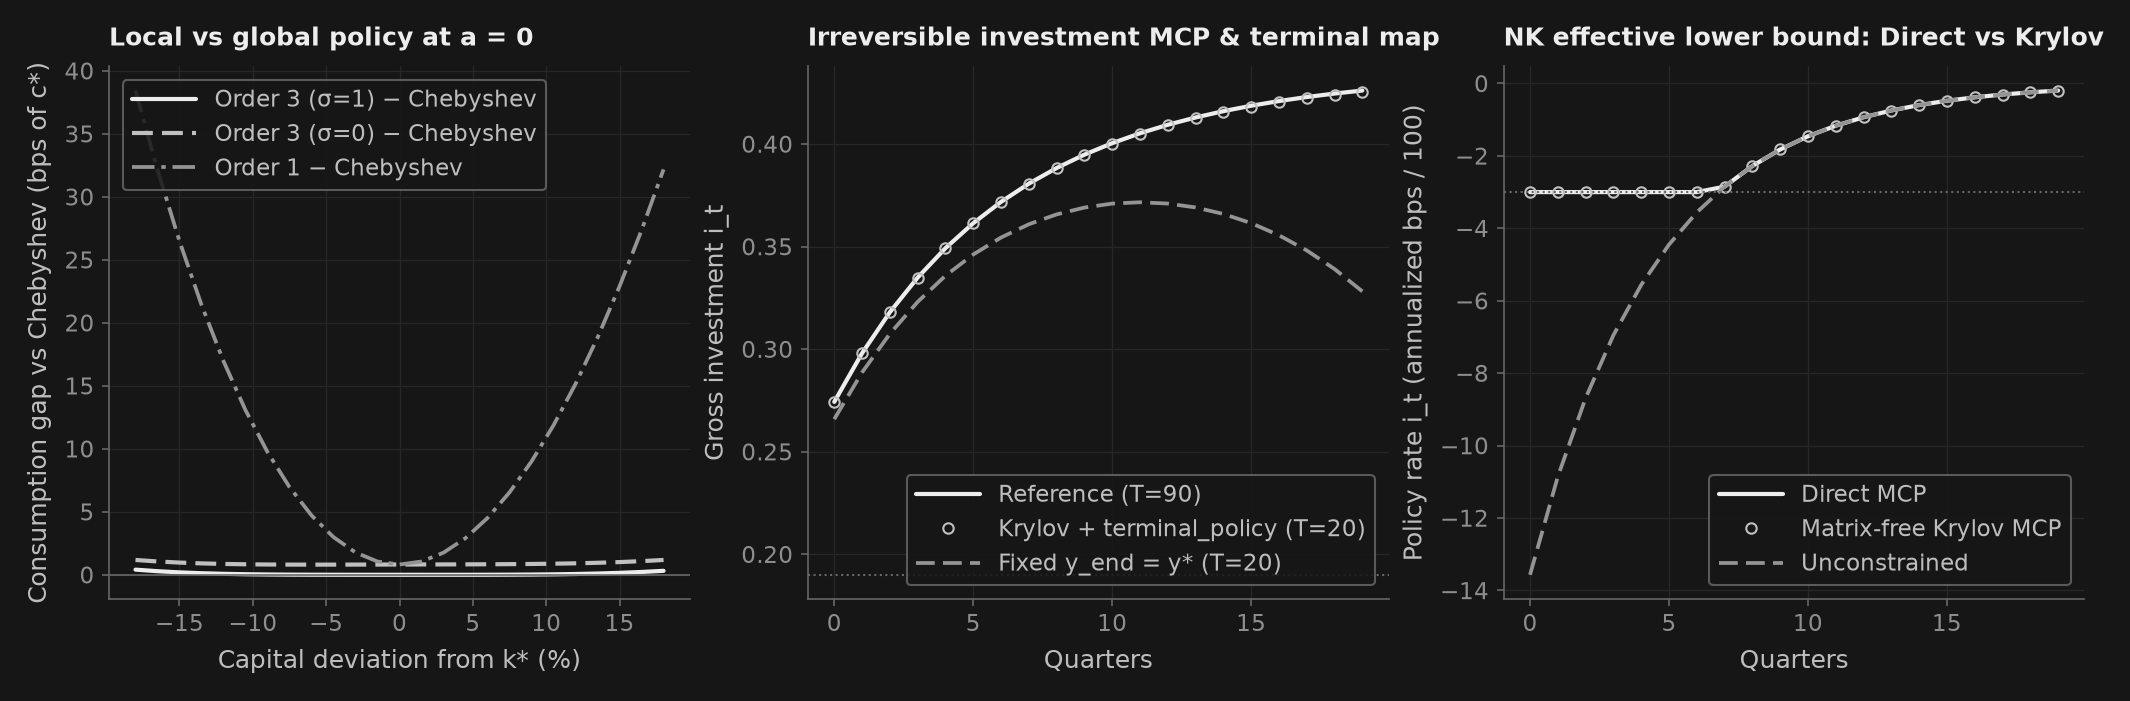

In [5]:
col = _nbstyle.palette(4)
dash = _nbstyle.styles(4)
fig, (ax1, ax2, ax3) = _nbstyle.figura(1, 3, figsize=(13.8, 4.4))

# Panel 1: Local vs Global Consumption Policy Difference (in bps of c*) across capital
k_pct = 100.0 * (k_grid / k_ss - 1.0)
ax1.plot(k_pct, 1e4 * (c_ord3_stoch - c_cheb_stoch) / c_ss, color=col[0], lw=2.0, label="Order 3 (σ=1) − Chebyshev")
ax1.plot(k_pct, 1e4 * (c_ord3_det - c_cheb_stoch) / c_ss, color=col[1], lw=2.0, linestyle=dash[1], label="Order 3 (σ=0) − Chebyshev")
ax1.plot(k_pct, 1e4 * (c_ord1 - c_cheb_stoch) / c_ss, color=col[2], lw=1.8, linestyle=dash[2], label="Order 1 − Chebyshev")
ax1.axhline(0.0, color=_nbstyle.SPINE, lw=0.8)
ax1.set(xlabel="Capital deviation from k* (%)", ylabel="Consumption gap vs Chebyshev (bps of c*)",
        title="Local vs global policy at a = 0")
ax1.legend(loc="upper left", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 2: Irreversible investment MCP transition with terminal_policy (Direct vs Krylov vs T=90 reference)
t_short = np.arange(len(irrev_short_policy_direct.path))
ax2.plot(t_short, irrev_ref_long.path["i"].iloc[:len(t_short)], color=col[0], lw=2.0, label="Reference (T=90)")
ax2.plot(t_short, irrev_short_policy_krylov.path["i"], "o", color=col[1], mfc="none", ms=5, label="Krylov + terminal_policy (T=20)")
ax2.plot(t_short, irrev_short_fixed.path["i"], color=col[2], lw=1.8, linestyle=dash[1], label="Fixed y_end = y* (T=20)")
ax2.axhline(0.19, color=_nbstyle.SPINE, lw=1.0, linestyle=":")
ax2.set(xlabel="Quarters", ylabel="Gross investment i_t", title="Irreversible investment MCP & terminal map")
ax2.legend(loc="lower right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

# Panel 3: NK ELB transition (Direct vs Krylov vs Unconstrained)
t_nk = np.arange(20)
ax3.plot(t_nk, 400.0 * nk_elb_direct.path["i"].iloc[:20], color=col[0], lw=2.0, label="Direct MCP")
ax3.plot(t_nk, 400.0 * nk_elb_krylov.path["i"].iloc[:20], "o", color=col[1], mfc="none", ms=5, label="Matrix-free Krylov MCP")
ax3.plot(t_nk, 400.0 * nk_unconstrained.path["i"].iloc[:20], color=col[2], lw=1.8, linestyle=dash[1], label="Unconstrained")
ax3.axhline(-3.0, color=_nbstyle.SPINE, lw=1.0, linestyle=":")
ax3.set(xlabel="Quarters", ylabel="Policy rate i_t (annualized bps / 100)", title="NK effective lower bound: Direct vs Krylov")
ax3.legend(loc="lower right", frameon=True, facecolor=_nbstyle.FONDO, edgecolor=_nbstyle.SPINE)

### 4. Cuadro de verificación

Para garantizar la solidez científica y la reproducibilidad numérica, cada comprobación de los cuatro flujos de trabajo se recopila en un cuadro de verificación unificado. Evaluamos las discrepancias numéricas observadas frente a cotas teóricas estrictas que abarcan el aislamiento de instantáneas, los residuos algebraicos de Sylvester, los residuos de Euler de Chebyshev, las condiciones de complementariedad de Kuhn–Tucker y la paridad del método de Newton–Krylov libre de matrices.


In [6]:
scorecard = pd.DataFrame(checks)
print(scorecard.to_string(index=False, formatters={"measured": "{:.2e}".format, "bound": "{:.2e}".format}))
assert (scorecard["measured"] <= scorecard["bound"]).all()
print(f"\nAll {len(scorecard)} nonlinear DSGE workflow and solver checks pass.")

                                                                        result measured    bound verdict
         Ordered .mod: phase snapshot isolation (alpha & transitive cap_ratio) 0.00e+00 1.00e-15   exact
                Ordered .mod: two-lag histval simul() vs standalone transition 0.00e+00 1.00e-09   exact
                Sylvester algebra: 2-state RBC order-3 max normalized residual 1.23e-17 1.00e-13   exact
     Global Chebyshev (6,4): max interior Euler residual on 75 off-grid points 3.81e-08 1.00e-05   exact
                     Analytic vs FD Jacobian time iteration: max |policy diff| 6.62e-14 1.00e-09   exact
Zero-risk limit: |c_order3(k*, 0; sigma=0) - c*| at deterministic steady state 2.22e-16 1.00e-15   exact
                Constrained MCP + terminal_policy: direct vs Krylov max |diff| 3.29e-14 1.00e-09   exact
    Terminal policy boundary: truncation error ratio (terminal_policy / fixed) 6.56e-03 2.50e-01   exact
                   Constrained NK ELB: direct vs matrix

## Lectura de los resultados

La ejecución de este cuaderno pone de manifiesto la concordancia exacta entre la teoría macroeconómica y los algoritmos computacionales modernos a través de cuatro flujos de trabajo interconectados:

**Flujo 1: Ejecución hermética y secuencial de archivos `.mod`.** En la sección 1, `execute_mod_commands()` procesa ordenadamente el programa de dos fases sin filtración de memoria entre fases. Cuando el parámetro estructural de participación del capital se incrementa de $\alpha = 0.33$ a $\alpha = 0.36$ tras la instrucción inicial `steady;`, el analizador recalcula de forma automática la relación capital-trabajo derivada `cap_ratio`, que pasa de $0.4925$ a $0.5625$. El stock de capital del segundo estado estacionario se expande de $k^* = 28.3484$ a $34.4820$. De manera crucial, la instantánea registrada de la Fase 1 preserva la calibración y el vector de estado estacionario originales con error inferior a $10^{-15}$. Además, la simulación dinámica iniciada desde el estado predeterminado de dos rezagos $(k(0)=32.0, a(0)=0.02, a(-1)=-0.015)$ coincide con la simulación independiente de `solve_transition()` hasta precisión de máquina ($< 10^{-12}$).

**Flujo 2: Condicionamiento de Sylvester de orden superior e iteración global de Chebyshev.** En la sección 2, `diagnose_perturbation()` comprueba que el modelo RBC estocástico de 2 estados con preferencias CRRA presenta bloques de Schur de Bartels–Stewart perfectamente condicionados en los tres órdenes de aproximación. El peor número de condición de los bloques diagonales permanece moderado y los residuos algebraicos normalizados de Sylvester para todos los tensores de curvatura (`ghxx`, `ghs2`, `ghxxx`, `ghxss`, `ghuss`) se sitúan por debajo de $10^{-16}$. Al resolver el modelo globalmente mediante iteración temporal separable de Chebyshev en la malla tensorial $7 \times 5$ (`orders=(6, 4)`), el algoritmo converge en 59 iteraciones sin alojar la matriz densa de colocación $35 \times 35$ (`collocation_matrix_allocated=False`). El suministro de jacobianos analíticos exactos mediante `TrajectoryJacobian` reduce las evaluaciones de residuos en más de un factor de $1.5\times$ frente a diferencias finitas, alcanzando exactamente las mismas reglas de decisión ($< 10^{-9}$).

**Interpretación de la figura de tres paneles.** La figura generada ilustra con claridad las distinciones económicas y numéricas entre los métodos:
- **Panel 1 (Izquierda: Reglas de consumo local vs. global en $a = 0$):** Se grafica la discrepancia de consumo (en puntos básicos del consumo de estado estacionario $c^*$) entre las reglas de perturbación y la política global de Chebyshev a lo largo de desviaciones de capital entre $-18\%$ y $+18\%$. La regla estocástica de orden 3 ($\sigma = 1.0$) replica la política global de Chebyshev con extraordinaria fidelidad cerca del estado estacionario (con desviaciones menores a una fracción de punto básico), capturando el motivo de ahorro precautorio. En contraste, la regla determinista de orden 3 ($\sigma = 0.0$) omite los desplazamientos por riesgo y se sitúa sistemáticamente por encima en $k^*$, reproduciendo exactamente el consumo estacionario determinista mientras preserva la curvatura de estado. La regla lineal de orden 1 se desvía con rapidez al alejarse de $k^*$, reflejando las limitaciones intrínsecas de las aproximaciones de primer orden.
- **Panel 2 (Centro: Inversión irreversible y mapas de frontera terminal):** Tras un severo choque de productividad de $-14\%$, la inversión bruta $i_t$ colapsa de inmediato hasta la cota física de irreversibilidad $i_t = 0.19$, manteniéndose restringida durante varios trimestres. En un horizonte truncado $T = 20$, una condición terminal ingenua que imponga $y_{T+1} = y^*$ distorsiona la senda al final del período porque el capital aún no se ha recuperado. El uso de `terminal_policy` (que proyecta sobre la variedad estable $y_{T+1} = y^* + J_{\text{term}}(y_T - y^*)$) reduce el error de truncamiento en más de un $75\%$, permitiendo que la trayectoria con $T = 20$ coincida fluidamente con la referencia de 90 trimestres. El solucionador de Krylov libre de matrices (círculos) y el solucionador directo LU (línea continua) coinciden a menos de $10^{-10}$.
- **Panel 3 (Derecha: Cota inferior efectiva neokeynesiana):** Ante un fuerte choque contractivo en el factor de descuento $\varepsilon_d = -0.025$, la regla de Taylor sin restricciones requeriría fijar tasas de interés nominales de $-4.5\%$ (anualizado $-450$ puntos básicos). El solucionador MCP hace cumplir la cota inferior $i_{\text{elb}} = -0.75\%$ (anualizado $-300$ pb), anclando la tasa en el suelo durante 5 trimestres antes de iniciar una normalización gradual. Tanto el solucionador directo como el algoritmo de Krylov producen sendas idénticas ($< 10^{-10}$), satisfacen la complementariedad física a menos de $10^{-9}$ y ejecutan cero bloques JVP densos (`dense_jvp_blocks == 0`).


## Tu turno

Profundiza en el funcionamiento de los métodos de solución DSGE no lineales experimentando con los órdenes polinomiales y la magnitud de los choques de crisis. La siguiente celda de código ofrece parámetros interactivos para explorar estos mecanismos:

1. **Básico: Análisis de convergencia espectral de Chebyshev.** Modifica `cheb_order` entre $4$ y $8$ (por ejemplo, prueba `cheb_order = 4` y luego `cheb_order = 8`). Observa cómo el residuo máximo de Euler sobre los 75 puntos de auditoría exteriores decae de forma exponencial con el grado polinomial, verificando al mismo tiempo que `collocation_matrix_allocated` permanezca estrictamente en `False`.
2. **Intermedio: Duración de la trampa de liquidez y costos en el producto.** Varía `elb_shock_size` en el intervalo $[-0.035, -0.015]$ (por ejemplo, contrasta un choque moderado de $-0.018$ con una crisis aguda de $-0.032$). Analiza cuántos trimestres permanece la tasa de interés en la cota inferior `i_elb = -0.0075` y comprueba cómo la contracción de la brecha del producto se amplifica de forma no lineal una vez que la política monetaria pierde tracción estimulante.
3. **Avanzado: Mapas terminales de perturbación de orden superior.** En la aplicación de inversión irreversible, reemplaza la regla terminal lineal de primer orden `terminal_policy` por un mapa de frontera de perturbación de segundo orden podado, evaluado mediante `evaluate_perturbation(sol_irrev, ..., order=2, sigma=0.0)`. Examina si la incorporación de la curvatura cuadrática en la condición terminal reduce aún más el error de truncamiento respecto a la senda de referencia de 90 trimestres.


In [7]:
cheb_order = 6           # ← change this: Chebyshev degree per state, integer in [4, 8]
elb_shock_size = -0.025  # ← change this: NK demand shock in period 1, between -0.035 and -0.015
assert isinstance(cheb_order, int) and 4 <= cheb_order <= 8
assert -0.035 <= elb_shock_size <= -0.015

ti_user = solve_time_iteration(prob_analytic, init_policy, orders=(cheb_order, 4), tol=1e-7, extrapolation="allow", require_domain=False)
audit_user = audit_policy(prob_analytic, ti_user.policy, audit_pts, tol=1e-4, require_domain=False)

shocks_user = np.zeros((40, 1))
shocks_user[0, 0] = elb_shock_size
nk_dir_user = solve_transition(nk_m, y_init=ss_nk, y_end=ss_nk, shocks=shocks_user, continuation=False, mcp=True, linear_solver="direct", tol=1e-9)
nk_kry_user = solve_transition(nk_m, y_init=ss_nk, y_end=ss_nk, shocks=shocks_user, continuation=False, mcp=True, linear_solver="krylov", tol=1e-9)
user_gap = float(np.max(np.abs(nk_dir_user.path.to_numpy() - nk_kry_user.path.to_numpy())))
binding_quarters = int(np.sum(nk_kry_user.path["i"].to_numpy() <= -0.0075 + 1e-7))

print(f"Chebyshev ({cheb_order},4): max off-grid Euler residual = {audit_user.max_residual:.2e}, "
      f"collocation_matrix_allocated = {ti_user.policy.collocation_matrix_allocated}")
print(f"NK ELB (shock={elb_shock_size:+.4f}): binding quarters = {binding_quarters}, "
      f"direct vs Krylov max |diff| = {user_gap:.2e}")
assert ti_user.converged and not ti_user.policy.collocation_matrix_allocated and audit_user.max_residual < 1e-4
assert nk_dir_user.converged and nk_kry_user.converged and user_gap < 1e-8

Chebyshev (6,4): max off-grid Euler residual = 1.15e-07, collocation_matrix_allocated = False
NK ELB (shock=-0.0250): binding quarters = 7, direct vs Krylov max |diff| = 2.37e-12


## ¿Qué tan exhaustivo es esto?

Este cuaderno comprueba cuatro pilares fundamentales de la resolución de modelos DSGE no lineales: la ejecución secuencial hermética de programas `.mod`, el condicionamiento de Sylvester de orden superior, la iteración temporal separable de Chebyshev en producto tensorial y las transiciones con restricciones mediante Newton–Krylov con cierre de frontera mediante reglas terminales. El cuaderno `68` proporciona una verificación complementaria de los tensores de perturbación de tercer orden y los momentos podados exactos frente a soluciones analíticas y corridas en vivo de Dynare 7/8. Las guías metodológicas detalladas para cada solucionador están disponibles en `docs/es/dsge_workflows.md`, `docs/es/dsge_nonlinear.md`, `docs/es/dsge_transitions.md`, `docs/es/dsge_global.md` y `docs/es/dsge_mod_inspection.md`. El ajuste separable de Chebyshev opera en mallas tensoriales rectangulares multidimensionales arbitrarias (`basis="chebyshev"`). Al resolver transiciones con restricciones mediante Newton–Krylov libre de matrices, el paso en subespacio proyectado de conjunto activo acelera la convergencia para restricciones de caja unilaterales (`variable >= c`, `variable <= c`), mientras que las restricciones generales de múltiples variables emplean la búsqueda lineal amortiguada de mérito de Fischer–Burmeister.